<a href="https://colab.research.google.com/github/mashaellna77-maker/international-airpassengers-project/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import os

if not os.path.exists("/content/proj"):
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj

%cd /content/proj
%pip install -q -e .
%pip install -q autogluon.timeseries

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12
H_REPORT = 24

print("ready")

/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for international-airpassengers-project (pyproject.toml) ... done
ready


---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [2]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [3]:
n_obs = len(df)
range_ = (df["ds"].min(), df["ds"].max())

expected_dates = pd.date_range(
    start=range_[0],
    end=range_[1],
    freq="MS"
)

n_gaps = len(expected_dates.difference(pd.DatetimeIndex(df["ds"])))

print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

144 months, 1949-01-01 to 1960-12-01, 0 gaps


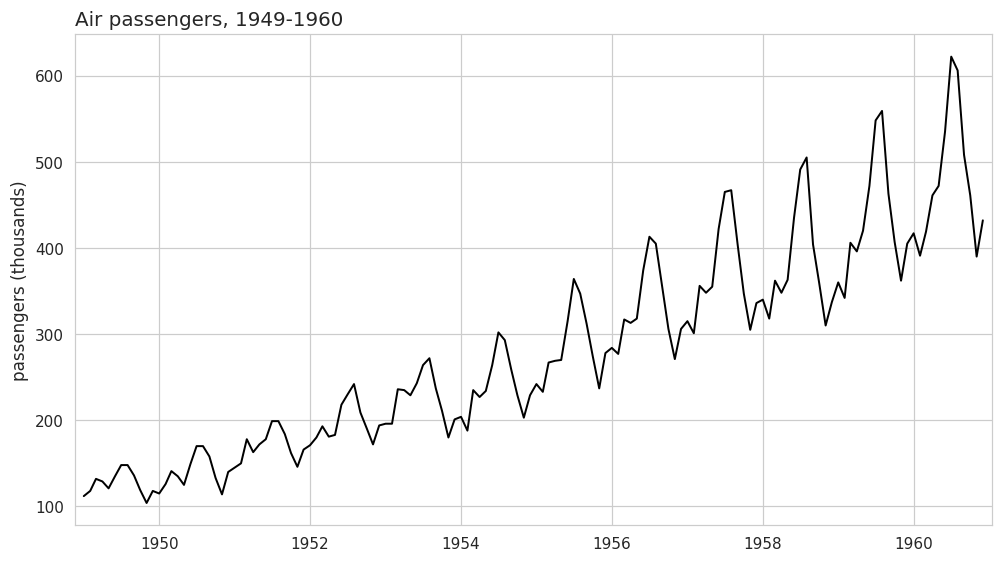

In [4]:
P.plot_series(df, title="Air passengers, 1949-1960",
              ylabel="passengers (thousands)", xlabel="")
plt.show()

Passenger numbers rise over time, with peaks and troughs repeating approximately every 12 months. The seasonal swings become larger as passenger numbers increase, suggesting that a log transformation or multiplicative seasonality may be useful.

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

/tmp/ipykernel_23632/1320473150.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


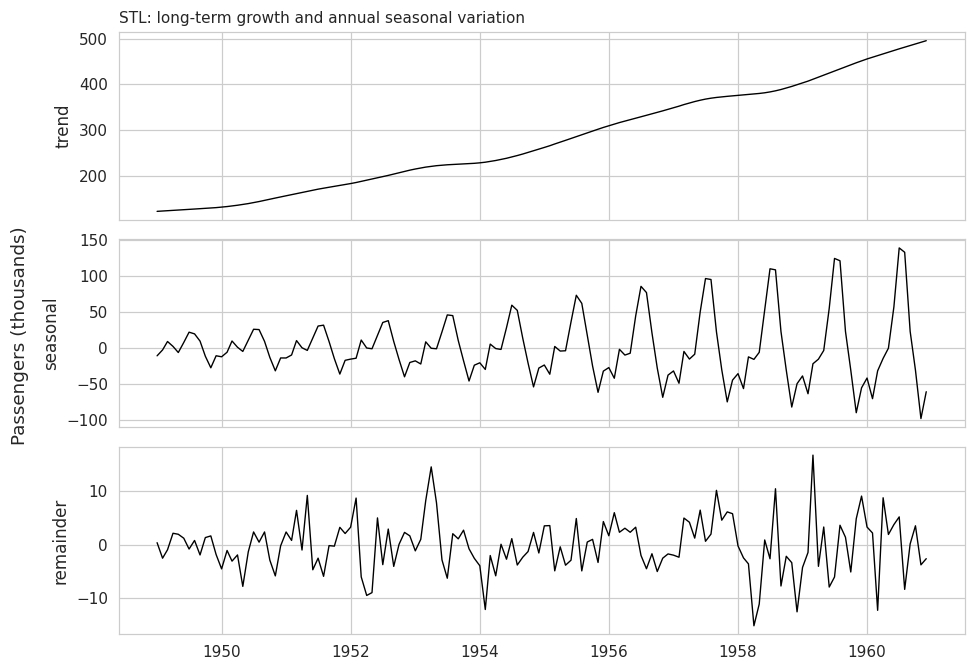

In [5]:
from statsmodels.tsa.seasonal import STL

stl = STL(df["y"].to_numpy(), period=12).fit()

dcmp = pd.DataFrame({
    "ds": df["ds"].to_numpy(),
    "trend": stl.trend,
    "seasonal": stl.seasonal,
    "remainder": stl.resid
})

P.decomposition_plot(
    dcmp,
    cols=["trend", "seasonal", "remainder"],
    title="STL: long-term growth and annual seasonal variation",
    x="ds",
    ylabel="Passengers (thousands)",
    panel_height=1.8
)

plt.tight_layout()
plt.show()

The trend explains the long-term rise in passenger numbers, while seasonality captures recurring annual peaks and troughs whose size increases over time. The remainder is much smaller and fluctuates around zero, with some spikes and larger variation near the end; the plot alone does not establish white noise.

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [6]:
remainder = dcmp["remainder"]

trend_strength = max(
    0,
    1 - np.var(remainder) / np.var(dcmp["trend"] + remainder)
)

seasonal_strength = max(
    0,
    1 - np.var(remainder) / np.var(dcmp["seasonal"] + remainder)
)

print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.99


Trend strength is approximately 1.00 and seasonal strength is 0.99, indicating very strong growth and annual seasonality. This motivates testing models that capture both, such as seasonal ETS or seasonal ARIMA, against Seasonal Naive; cross-validation will determine which performs best.

**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

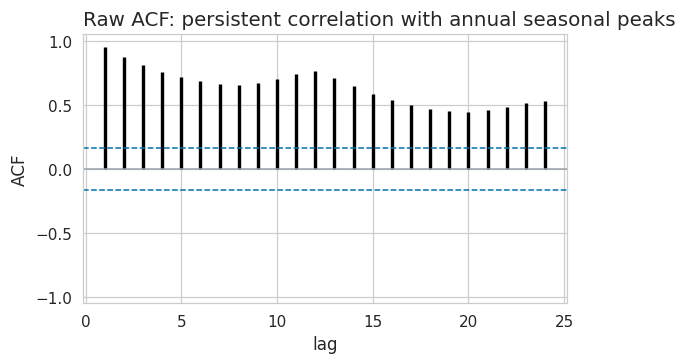

In [7]:
# TODO: ACF plot of df["y"] (P.acf_plot), 24 lags.
P.acf_plot(
    df["y"],
    nlags=24,
    title="Raw ACF: persistent correlation with annual seasonal peaks"
)
plt.show()

The ACF stays strongly positive and declines slowly, consistent with the rising trend. Local peaks at lags 12 and 24 indicate that passenger numbers one and two years apart are related, supporting annual seasonality; models should account for both trend and seasonality.

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS",
    n_jobs=1
)

floor_fc = floor_sf.forecast(
    df=df,
    h=H_REPORT,
    level=scoring.LEVELS
)

floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,447.564102,463.5405,488.177552
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,421.564102,437.5405,462.177552
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,449.564102,465.5405,490.177552
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,491.564102,507.5405,532.177552
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,502.564102,518.5405,543.177552


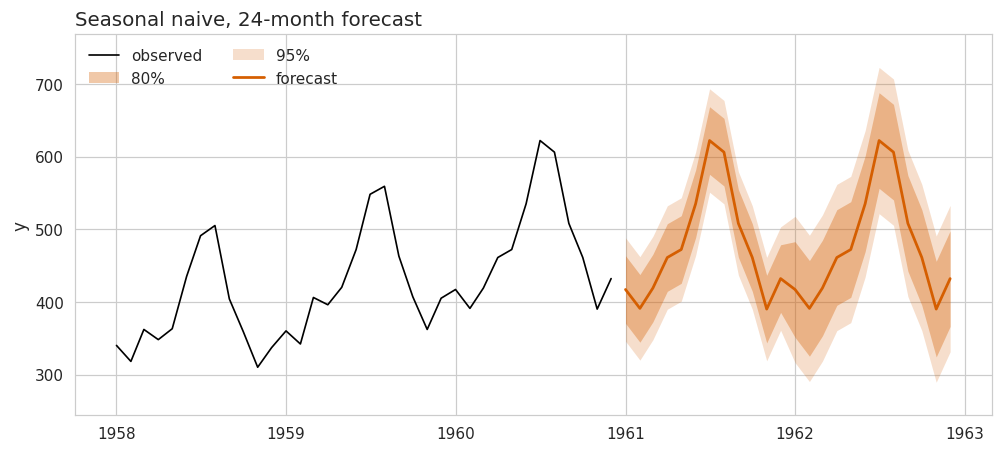

In [9]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

Seasonal Naive repeats the 1960 monthly pattern for 1961 and 1962, preserving seasonality without extending the upward trend. The 95% prediction band is wider than the 80% band, and both widen in the second forecast year; their actual coverage must be checked using historical backtesting.

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

/tmp/ipykernel_23632/1812084148.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


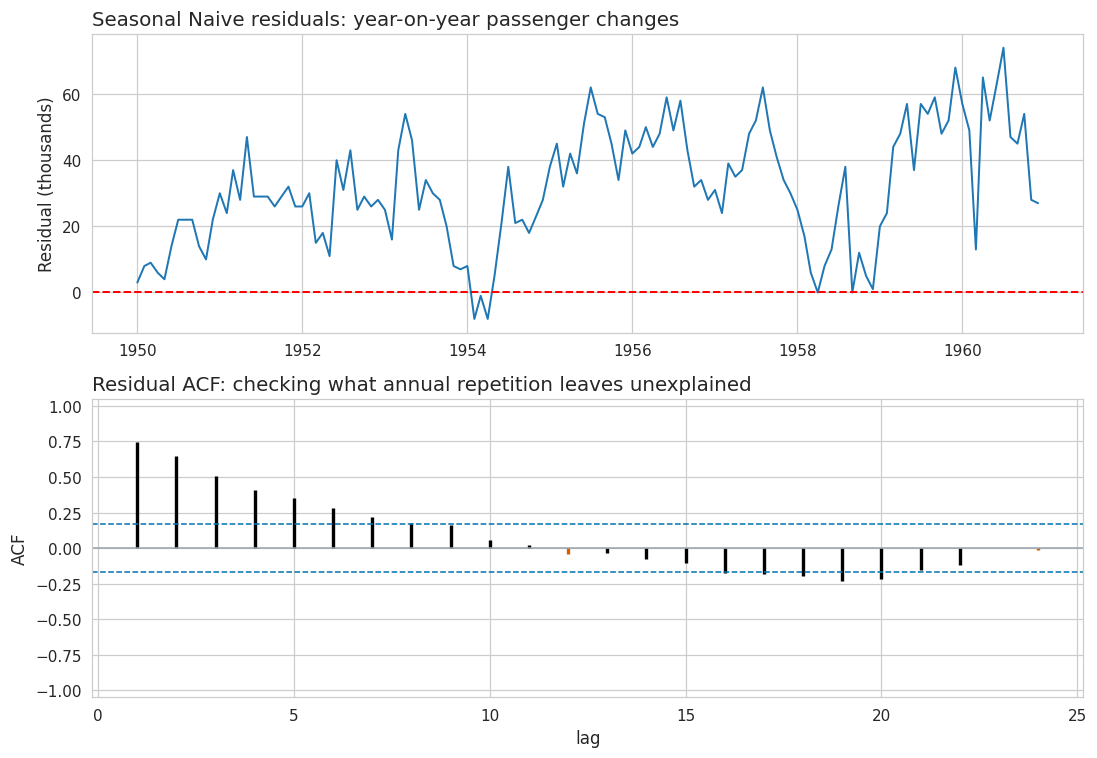

Mean residual: 31.77


In [10]:
# TODO: the floor's residuals (y_t - y_{t-12}), a plot of them, and their
#       ACF with P.acf_plot (24 lags, highlight_every=SEASON_LENGTH).
# الفرق بين كل شهر والشهر نفسه من السنة السابقة
resid_floor = df["y"].diff(SEASON_LENGTH).dropna()

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(df["ds"].iloc[SEASON_LENGTH:], resid_floor)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Seasonal Naive residuals: year-on-year passenger changes")
axes[0].set_ylabel("Residual (thousands)")

P.acf_plot(
    resid_floor,
    nlags=24,
    ax=axes[1],
    highlight_every=SEASON_LENGTH,
    title="Residual ACF: checking what annual repetition leaves unexplained"
)

plt.tight_layout()
plt.show()

print(f"Mean residual: {resid_floor.mean():.2f}")

Seasonal Naive underpredicts by an average of 31.77 thousand passengers, showing that repeating last year misses growth. Strong positive autocorrelation at short lags indicates remaining structure, while lag 12 is close to zero; the residuals are not white noise. Trend-aware ETS or seasonal ARIMA may capture this structure, subject to cross-validation.

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [11]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [12]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows


In [13]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [14]:
# TODO: display the leaderboard on the held-out months (predictor.leaderboard(tsdf)).
#       Read it: what is the SIGN of score_val, which models did it fit, and
#       how many windows did it score them on?
if HAS_AG:
    leaderboard = predictor.leaderboard(tsdf)
    display(leaderboard)

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoARIMA,-0.608073,-1.575987,0.292740,0.249578,0.038583,5
1,Theta,-0.875371,-1.633923,0.067464,0.045987,0.047745,3
2,WeightedEnsemble,-0.929514,-1.535792,0.595500,0.551366,0.581948,6
3,AutoETS,-1.169539,-1.554323,0.294626,0.296204,0.055321,4
4,SeasonalNaive,-1.570881,-1.656513,0.017563,0.032723,0.043636,2
5,Naive,-2.495895,-3.196371,0.014721,0.032295,0.061967,1


AutoGluon reports negative MASE, so higher scores are better. WeightedEnsemble leads on internal validation, while AutoARIMA performs best on the 12 held-out months, with MASE 0.608 versus 1.571 for Seasonal Naive. Theta failed and fell back to Seasonal Naive. This single holdout is preliminary evidence; the final comparison uses eight rolling-origin windows.

**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

The internal validation used one window, while score_test evaluates the separate final 12-month holdout. Scores are negative MASE, so values closer to zero are better. This ranking provides a shortlist rather than reliable evidence across different periods. Shortlisting seasonal AutoARIMA is consistent with the strong trend and annual seasonality identified in section 1.

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [15]:
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8,
                            level=scoring.LEVELS)
cv.head()

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884


In [16]:
# TODO: pick the model your leaderboard shortlists (the statsforecast twin
#       of the winner: AutoTheta / AutoETS / AutoARIMA ...), cross-validate
#       it over the SAME folds, and put BOTH models in one table - one row
#       per model: mase, rmsse, crps, coverage_80 (plus the min/max MASE).
from statsforecast.models import AutoARIMA, Naive

MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)
MY_NAME = "AutoARIMA"

mysf = StatsForecast(
    models=[MY_MODEL, Naive()],
    freq="MS",
    n_jobs=1
)

mycv = mysf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=scoring.LEVELS
)

assert set(cv["cutoff"]) == set(mycv["cutoff"])

RESULTS = pd.DataFrame({
    "SeasonalNaive": scoring.score_cv(
        cv, "SeasonalNaive", df,
        seasonality=SEASON_LENGTH
    ),
    MY_NAME: scoring.score_cv(
        mycv, MY_NAME, df,
        seasonality=SEASON_LENGTH
    ),
    "Naive": scoring.score_cv(
        mycv, "Naive", df,
        seasonality=SEASON_LENGTH
    )
}).T

display(RESULTS.round(3))

,mase,rmsse,crps,coverage_80,mase_min,mase_max
SeasonalNaive,1.313,1.246,0.062,0.510,0.412,1.959
AutoARIMA,0.647,0.683,0.034,0.698,0.330,1.594
Naive,2.119,2.452,0.110,0.688,1.422,3.196


Across eight rolling-origin windows (h=12, step=12), AutoARIMA supports the leaderboard’s shortlist. It improves on Seasonal Naive in MASE (0.647 versus 1.313), RMSSE (0.683 versus 1.246), and scaled CRPS (0.034 versus 0.062). Its 80% interval coverage improves from 51.0% to 69.8%, but remains below the nominal 80%, indicating underestimated uncertainty. Naive performs worse on point and distributional scores and also undercovers at 68.8%. AutoARIMA wins on average, but its worst-window MASE of 1.594 shows that performance varies across periods; its intervals need improvement.

**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

,model,mean_width_80,coverage_80
0,SeasonalNaive,77.758,0.510
1,AutoARIMA,44.076,0.698
2,Naive,142.947,0.688


/tmp/ipykernel_23632/3914241836.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


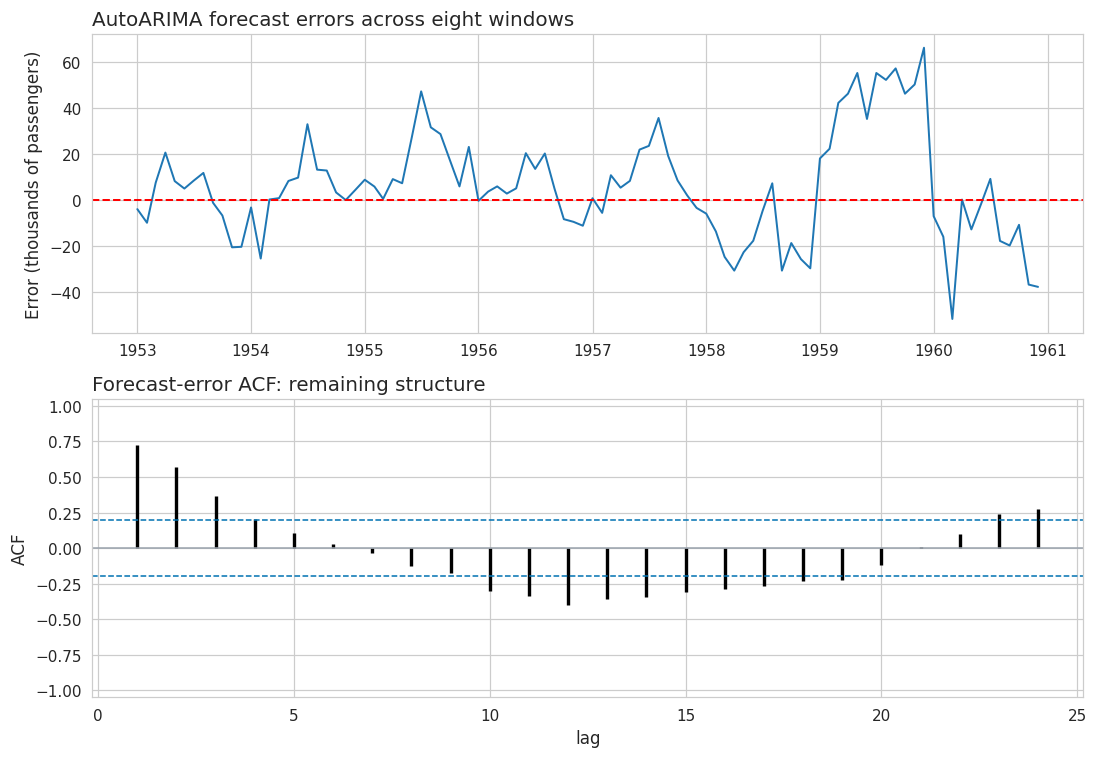

Mean forecast error: 5.88


In [17]:
interval_summary = pd.DataFrame([
    {
        "model": name,
        "mean_width_80": (
            data[f"{name}-hi-80"]
            - data[f"{name}-lo-80"]
        ).mean(),
        "coverage_80": RESULTS.loc[name, "coverage_80"]
    }
    for name, data in [
        ("SeasonalNaive", cv),
        ("AutoARIMA", mycv),
        ("Naive", mycv)
    ]
])

display(interval_summary.round(3))

errors = mycv.sort_values("ds").copy()
errors["error"] = errors["y"] - errors[MY_NAME]

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(errors["ds"], errors["error"])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("AutoARIMA forecast errors across eight windows")
axes[0].set_ylabel("Error (thousands of passengers)")

P.acf_plot(
    errors["error"],
    nlags=24,
    ax=axes[1],
    title="Forecast-error ACF: remaining structure"
)

plt.tight_layout()
plt.show()

print(f"Mean forecast error: {errors['error'].mean():.2f}")

AutoARIMA’s 80% prediction intervals have an average width of 44.076 thousand passengers, compared with 77.758 for Seasonal Naive and 142.947 for Naive. Despite being narrower, AutoARIMA achieves the highest coverage at 69.8%. However, all three models fall below the nominal 80%, so none achieves the intended coverage in this backtest. Wider intervals alone do not guarantee better coverage.

AutoARIMA’s mean out-of-sample forecast error is +5.88 thousand passengers, indicating average underprediction. Errors cluster above and below zero, with strong positive autocorrelation at short lags and negative correlation at lag 12. These are multi-step forecast errors from annual rolling origins, so dependence can arise within each forecast window; this ACF alone does not establish autocorrelation in the model’s one-step residuals. The remaining bias and 69.8% coverage suggest that uncertainty estimates need improvement.

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.